
# COS802 - Community Detection

## Research Question 1

How do Louvain, spectral clustering and label propagation compare in the quality, stability and speed of the communities they detect?

## Experiment E1: Community Detection Comparison

### Objectives

1. Implement Louvain, spectral clustering and label propagation.
2. Compare detected communities with known Karate Club factions.
3. Evaluate modularity, NMI, ARI, stability and runtime.
4. Investigate how algorithm behaviour changes across random seeds.

### Dataset

Zachary's Karate Club network:
- 34 nodes
- 78 undirected edges
- Two known factions

### Methodology

Community detection will be performed without using the known faction labels. These labels will only be used during evaluation.

All stochastic algorithms will be tested across multiple random seeds to assess the stability of their results.


In [1]:

import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.metrics import (
    normalized_mutual_info_score,
    adjusted_rand_score
)

# Load Karate Club network
G = nx.karate_club_graph()

# Store the known faction labels for evaluation
nodes = list(G.nodes())

true_labels = [
    G.nodes[node]["club"]
    for node in nodes
]

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Known factions:", set(true_labels))


Nodes: 34
Edges: 78
Known factions: {'Officer', 'Mr. Hi'}


In [2]:

#Louvain community detection
start_time = time.perf_counter()

louvain_communities = nx.community.louvain_communities(
    G,
    weight=None,
    resolution=1,
    seed=42
)

runtime = time.perf_counter() - start_time

print("Number of communities:", len(louvain_communities))
print("Runtime (seconds):", round(runtime, 6))

for i, community in enumerate(louvain_communities, start=1):
    print(f"Community {i}: {sorted(community)}")


Number of communities: 3
Runtime (seconds): 0.003799
Community 1: [0, 1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 13, 16, 17, 19, 21]
Community 2: [24, 25, 28, 31]
Community 3: [8, 14, 15, 18, 20, 22, 23, 26, 27, 29, 30, 32, 33]


In [3]:

# Convert community sets into node labels
predicted = {}

for community_id, community in enumerate(louvain_communities):
    for node in community:
        predicted[node] = community_id

predicted_labels = [predicted[node] for node in nodes]

# Community quality
modularity = nx.community.modularity(
    G,
    louvain_communities,
    weight=None
)

# Agreement with known factions
nmi = normalized_mutual_info_score(
    true_labels,
    predicted_labels
)

ari = adjusted_rand_score(
    true_labels,
    predicted_labels
)

print("Louvain Evaluation")
print("------------------")
print("Modularity:", round(modularity, 4))
print("NMI:", round(nmi, 4))
print("ARI:", round(ari, 4))
print("Runtime (seconds):", round(runtime, 6))


Louvain Evaluation
------------------
Modularity: 0.3854
NMI: 0.5757
ARI: 0.6124
Runtime (seconds): 0.003799


## Louvain Community Visualisation

We compare the communities detected by Louvain with the known Karate Club factions.

The same network layout is used for both visualisations to make structural differences easier to identify.

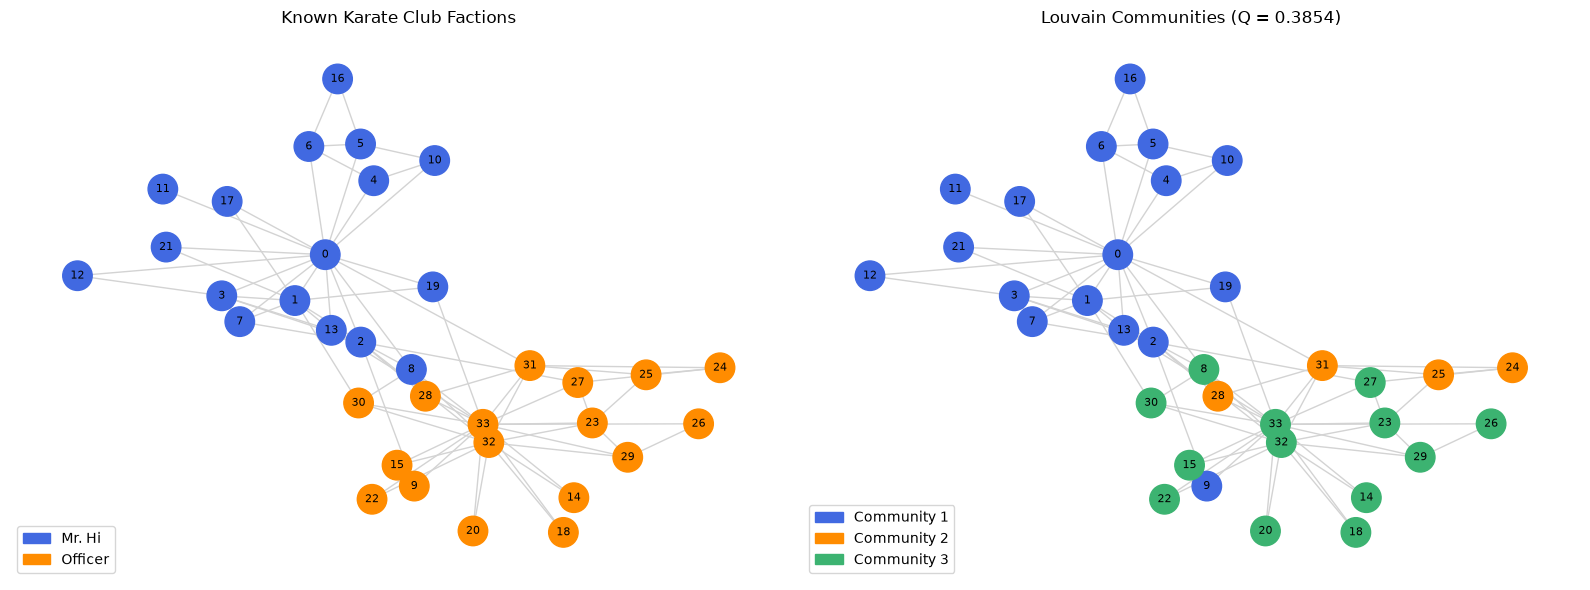

Figure saved: C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis\figures\karate_louvain_vs_known.png


In [8]:

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Fixed layout for both plots
pos = nx.spring_layout(G, seed=42)

# Known faction colours
faction_colors = {
    "Mr. Hi": "royalblue",
    "Officer": "darkorange"
}

known_colors = [
    faction_colors[G.nodes[node]["club"]]
    for node in G.nodes()
]

# Louvain community colours
community_palette = [
    "royalblue",
    "darkorange",
    "mediumseagreen"
]

louvain_colors = [
    community_palette[predicted[node]]
    for node in G.nodes()
]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Known factions
nx.draw_networkx(
    G,
    pos=pos,
    ax=axes[0],
    node_color=known_colors,
    node_size=450,
    font_size=8,
    edge_color="lightgray"
)

axes[0].set_title("Known Karate Club Factions")
axes[0].axis("off")

# Plot 2: Louvain communities
nx.draw_networkx(
    G,
    pos=pos,
    ax=axes[1],
    node_color=louvain_colors,
    node_size=450,
    font_size=8,
    edge_color="lightgray"
)

axes[1].set_title(
    f"Louvain Communities (Q = {modularity:.4f})"
)
axes[1].axis("off")

axes[0].legend(
    handles=[
        Patch(color=color, label=label)
        for label, color in faction_colors.items()
    ],
    loc="lower left"
)

axes[1].legend(
    handles=[
        Patch(
            color=community_palette[i],
            label=f"Community {i+1}"
        )
        for i in range(len(louvain_communities))
    ],
    loc="lower left"
)

plt.tight_layout()

# Save figure to project
from pathlib import Path
project_folder = (
    Path.home()
    / "Documents"
    / "University_Projects"
    / "cos802-network-analysis"
)


figure_path = (
    project_folder
    / "figures"
    / "karate_louvain_vs_known.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:", figure_path)


In [9]:

comparison_df = pd.DataFrame({
    "Node": nodes,
    "Known_Faction": true_labels,
    "Louvain_Community": [
        predicted[node] + 1 for node in nodes
    ]
})

faction_comparison = pd.crosstab(
    comparison_df["Known_Faction"],
    comparison_df["Louvain_Community"]
)

display(faction_comparison)


Louvain_Community,1,2,3
Known_Faction,,,
Mr. Hi,16,0,1
Officer,1,4,12


### Louvain Community Detection: Initial Findings

Louvain identified three communities in the Zachary Karate Club network, compared with the two known factions. The detected partition achieved a modularity score of 0.3854, NMI of 0.5757 and ARI of 0.6124.

The contingency table shows that Community 1 contains 16 of the 17 members belonging to the Mr. Hi faction, while the Officer faction is divided mainly between Communities 2 and 3. Two nodes show disagreement between the detected communities and the dominant faction membership of their assigned groups: node 8 belongs to Mr. Hi but was assigned to Community 3, while node 9 belongs to the Officer faction but was assigned to Community 1.

These findings indicate that Louvain recovered much of the known faction structure while identifying an additional subgroup within the Officer faction. This difference reflects the fact that Louvain optimises modularity rather than agreement with known faction labels.

However, these results are based on a single run. Further experiments using different random seeds are needed to determine whether the three-community structure is stable.

## Louvain Stability Analysis

We repeat Louvain community detection across 30 random seeds to investigate variation in community assignments, modularity and agreement with known factions.

In [10]:

import numpy as np
import time

stability_results = []
partitions = []

for seed in range(30):

    start = time.perf_counter()

    communities = nx.community.louvain_communities(
        G,
        weight=None,
        resolution=1,
        seed=seed
    )

    elapsed = time.perf_counter() - start

    # Assign community IDs to nodes
    labels_dict = {
        node: i
        for i, community in enumerate(communities)
        for node in community
    }

    labels = [labels_dict[node] for node in nodes]
    partitions.append(labels)

    stability_results.append({
        "seed": seed,
        "n_communities": len(communities),
        "modularity": nx.community.modularity(
            G, communities, weight=None
        ),
        "nmi": normalized_mutual_info_score(
            true_labels, labels
        ),
        "ari": adjusted_rand_score(
            true_labels, labels
        ),
        "runtime_seconds": elapsed
    })

df_stability = pd.DataFrame(stability_results)

display(df_stability.head(10))


,seed,n_communities,modularity,nmi,ari,runtime_seconds
0,0,4,0.419790,0.587850,0.464591,0.003215
1,1,4,0.418803,0.489967,0.392239,0.002326
2,2,4,0.418803,0.489967,0.392239,0.001621
3,3,4,0.415105,0.600011,0.508864,0.001562
4,4,4,0.415105,0.600011,0.508864,0.001734
5,5,4,0.415598,0.497679,0.429291,0.001683
6,6,4,0.418803,0.489967,0.392239,0.001666
7,7,4,0.418803,0.489967,0.392239,0.001710
8,8,4,0.419790,0.587850,0.464591,0.001729
9,9,4,0.418803,0.489967,0.392239,0.001540


In [11]:

summary = df_stability[
    ["n_communities", "modularity", "nmi",
     "ari", "runtime_seconds"]
].agg(["mean", "std", "min", "max"])

display(summary.round(4))

print("\nNumber of communities across runs:")
print(
    df_stability["n_communities"]
    .value_counts()
    .sort_index()
)


,n_communities,modularity,nmi,ari,runtime_seconds
mean,4.0,0.4155,0.5342,0.4414,0.0020
std,0.0,0.0058,0.0515,0.0489,0.0007
min,4.0,0.3952,0.4869,0.3698,0.0013
max,4.0,0.4198,0.6000,0.5089,0.0034



Number of communities across runs:
n_communities
4    30
Name: count, dtype: int64


In [12]:

from itertools import combinations

pairwise_ari = [
    adjusted_rand_score(partitions[i], partitions[j])
    for i, j in combinations(range(len(partitions)), 2)
]

print("Pairwise stability results")
print("--------------------------")
print("Mean pairwise ARI:", round(np.mean(pairwise_ari), 4))
print("Std pairwise ARI:", round(np.std(pairwise_ari), 4))
print("Minimum pairwise ARI:", round(np.min(pairwise_ari), 4))
print("Maximum pairwise ARI:", round(np.max(pairwise_ari), 4))


Pairwise stability results
--------------------------
Mean pairwise ARI: 0.8612
Std pairwise ARI: 0.096
Minimum pairwise ARI: 0.6355
Maximum pairwise ARI: 1.0


### Louvain Stability Analysis: Findings

Louvain was evaluated across 30 runs using different random seeds (0–29) to assess the stability of its community detection results.

All 30 runs identified four communities, indicating consistency in the number of detected groups. The mean modularity was 0.4155 (SD = 0.0058), with values ranging from 0.3952 to 0.4198.

The mean pairwise Adjusted Rand Index (ARI) between runs was 0.8612, indicating strong overall agreement in community assignments. However, the minimum pairwise ARI of 0.6355 shows that some variation occurred between runs.

Agreement with the known Karate Club factions was lower, with mean NMI and ARI values of 0.5342 and 0.4414, respectively.

Interestingly, the original seed-42 run produced three communities with lower modularity (0.3854) but higher agreement with the known factions (ARI = 0.6124). This demonstrates that maximising modularity does not necessarily produce communities that best match known group membership.

Overall, Louvain showed relatively stable community detection under the tested settings, although some node assignments varied across runs. These findings provide a baseline for comparison with spectral clustering and label propagation.

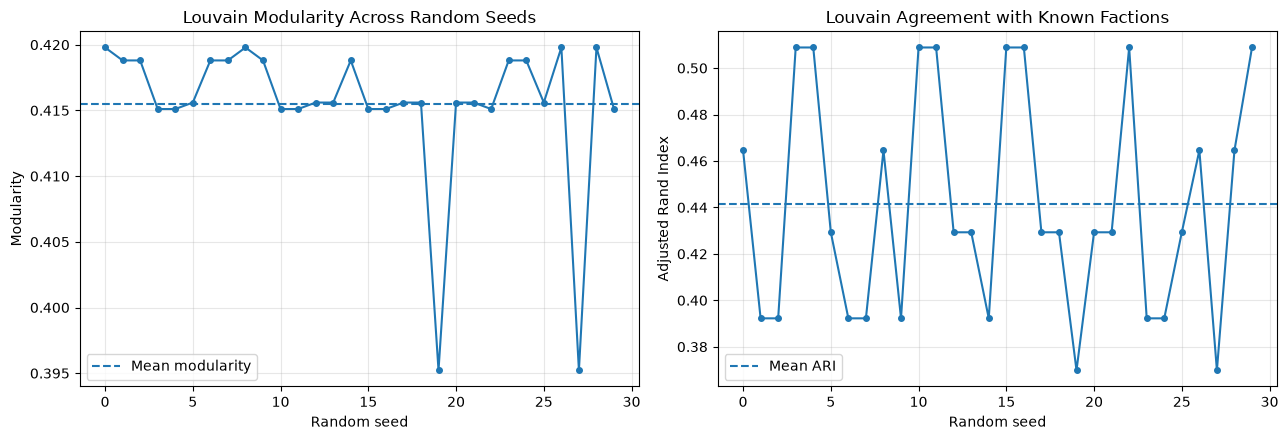

Saved: C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis\figures\karate_louvain_stability.png


In [13]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Modularity across seeds
axes[0].plot(
    df_stability["seed"],
    df_stability["modularity"],
    marker="o",
    markersize=4
)

axes[0].axhline(
    df_stability["modularity"].mean(),
    linestyle="--",
    label="Mean modularity"
)

axes[0].set_title("Louvain Modularity Across Random Seeds")
axes[0].set_xlabel("Random seed")
axes[0].set_ylabel("Modularity")
axes[0].legend()
axes[0].grid(alpha=0.3)

# ARI with known factions
axes[1].plot(
    df_stability["seed"],
    df_stability["ari"],
    marker="o",
    markersize=4
)

axes[1].axhline(
    df_stability["ari"].mean(),
    linestyle="--",
    label="Mean ARI"
)

axes[1].set_title("Louvain Agreement with Known Factions")
axes[1].set_xlabel("Random seed")
axes[1].set_ylabel("Adjusted Rand Index")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

output_path = (
    project_folder
    / "figures"
    / "karate_louvain_stability.png"
)

plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output_path)


In [14]:

results_path = project_folder / "results"

results_path.mkdir(parents=True, exist_ok=True)

df_stability.to_csv(
    results_path / "karate_louvain_stability.csv",
    index=False
)

print("Louvain stability results saved.")


Louvain stability results saved.
